### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DAFM = data.copy()
DAFM = DAFM[['date', 'price']]
DAFM['date'] = pd.to_datetime(DAFM['date'])
mask = (DAFM['date']>=obv_st_date) & (DAFM['date']<=obv_end_date)
DAFM = DAFM.loc[mask]
DAFM = DAFM.set_index('date')
DAFM.head()

,price
date,
2008-01-15,400.00
2008-01-15,3636.36
2008-01-15,3636.36
2008-01-15,242.42
2008-01-15,969.70


In [12]:
DAFM = DAFM.resample('MS').mean()
DAFM.head()

,price
date,
2008-01-01,1056.864390
2008-02-01,1136.594375
2008-03-01,1091.044937
2008-04-01,1011.162530
2008-05-01,1011.921319


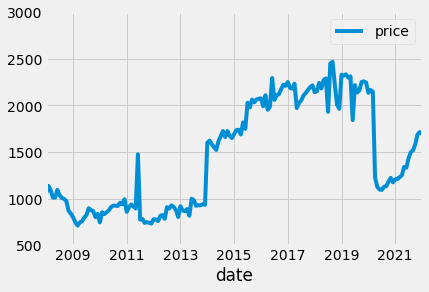

In [13]:
DAFM.plot(grid=True)
plt.show()

##### Checking Random Walk

In [14]:
RW_DAFM = adfuller(DAFM['price'])
RW_DAFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.584895297868178

##### Plotting ACF and PACF

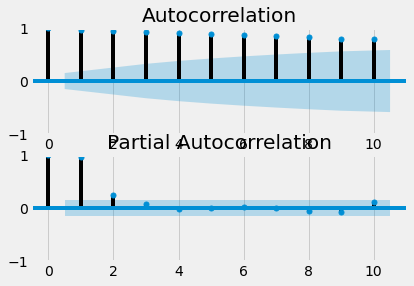

In [15]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFM, lags=10, ax=axes[0])
plot_pacf(DAFM, lags=10, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

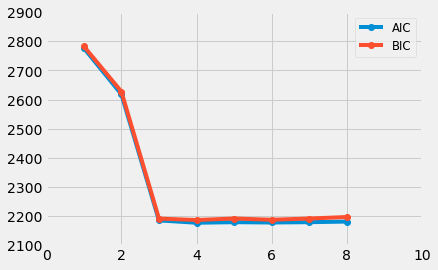

In [16]:
AIC, BIC = AIC_BIC_withOrderRange(DAFM, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [17]:
AIC, BIC

(array([2967.21901397, 2776.36771505, 2617.90826747, 2185.35121859,
        2177.3399133 , 2179.32266506, 2178.20767971, 2179.32454322,
        2181.34046366]),
 array([2970.34891268, 2782.62751248, 2627.29796362, 2191.61101602,
        2186.72960945, 2191.84225992, 2187.59737586, 2191.84413808,
        2196.98995723]))

##### We will run again 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [18]:
mod_orders = [
    (1, 0, 0),
    (1, 0, 1),
    (1, 0, 2), 
    (2, 0, 0),
    (2, 0, 1),
    (2, 0, 2)
]

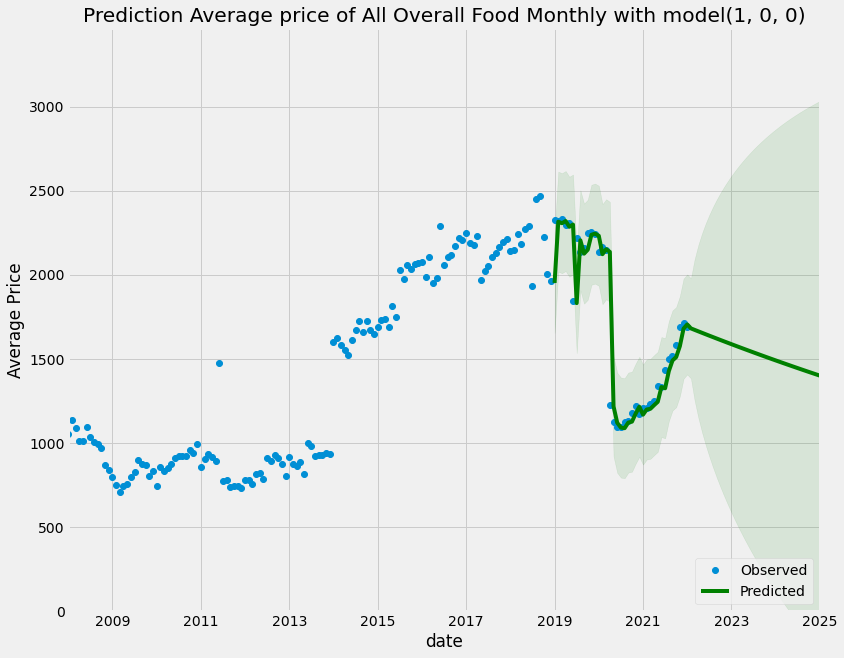

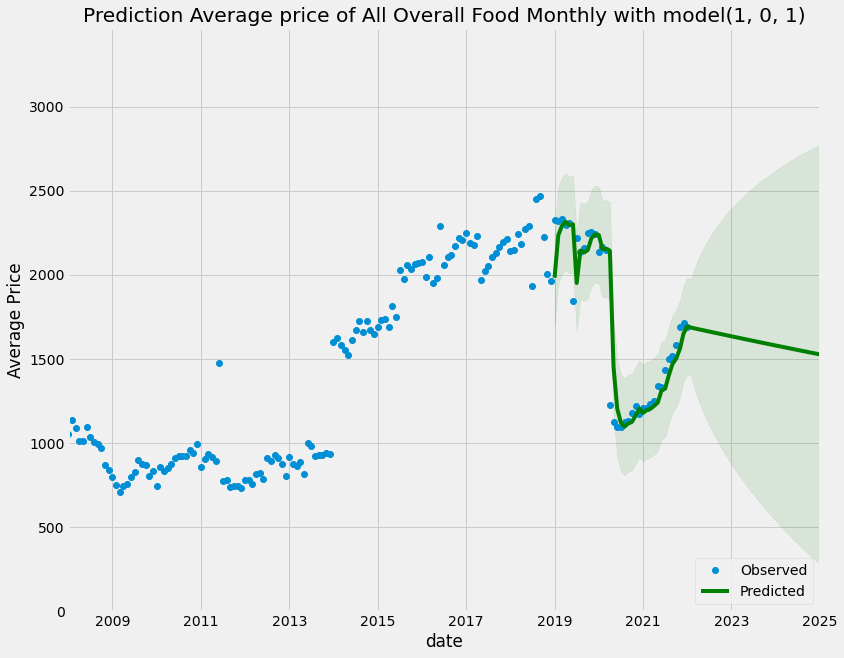

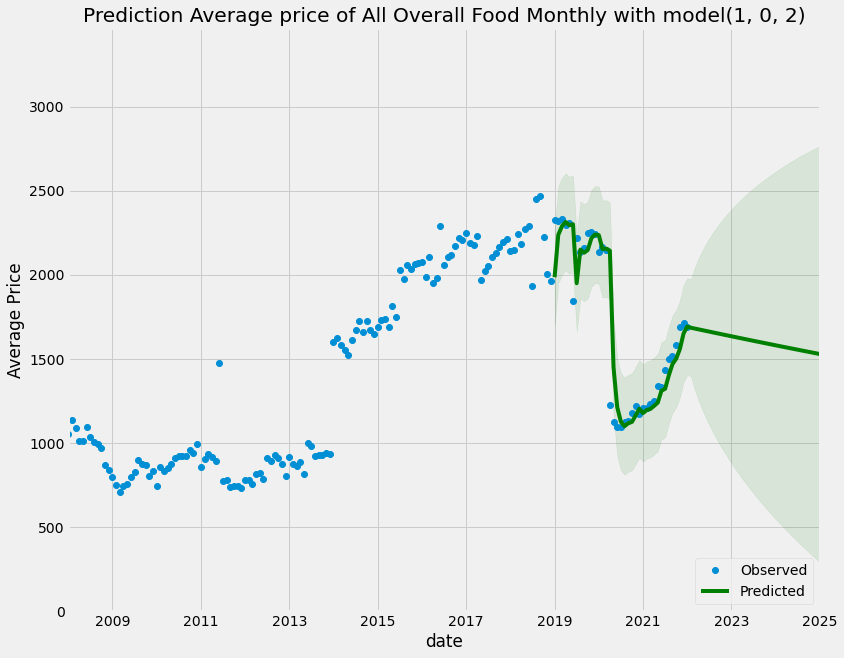

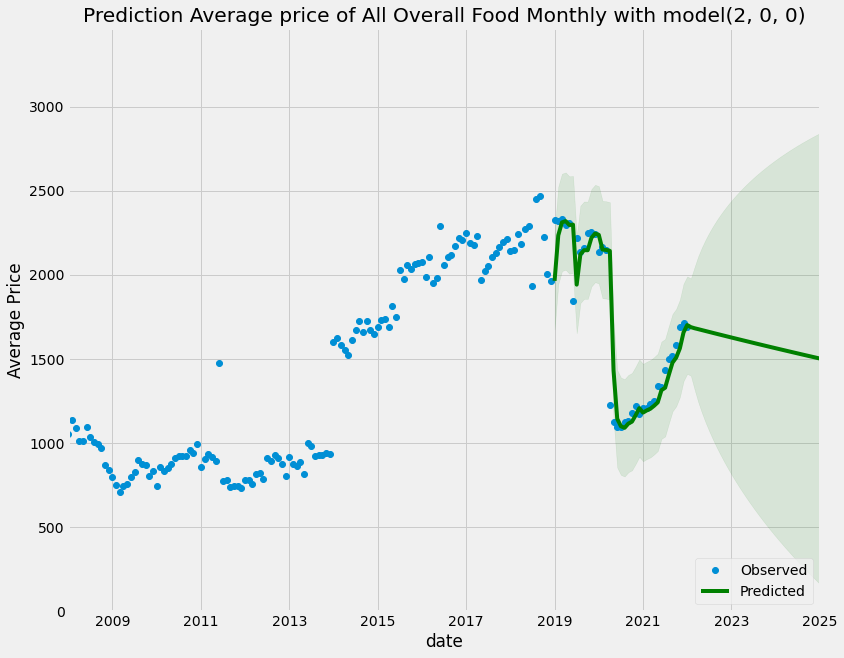

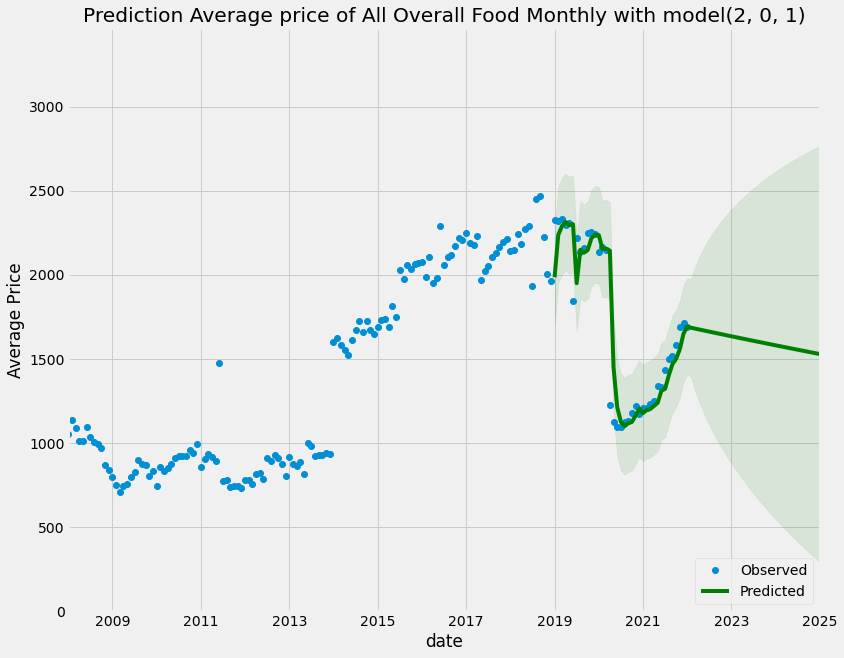

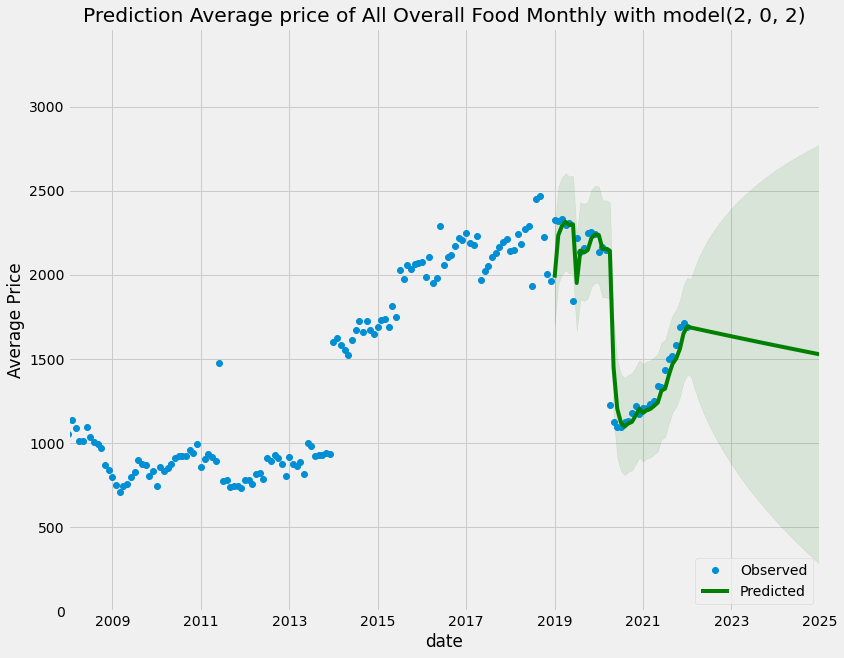

In [19]:
DAFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of All Overall Food Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DAFM_models.append(model)

Now we choose (1, 0, 0)

In [20]:
DAFM_model = DAFM_models[0]

In [21]:
DAFM_pred = DAFM_model.predict(pred_st_date, pred_end_date)
DAFM_pred

2019-01-01    1951.849767
2019-02-01    2316.141629
2019-03-01    2306.989148
2019-04-01    2319.840030
2019-05-01    2285.887669
                 ...     
2024-09-01    1430.362706
2024-10-01    1422.913623
2024-11-01    1415.503334
2024-12-01    1408.131635
2025-01-01    1400.798328
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64